# Data Analysis Notebook


Syed Zuhaib Ahmed 23BDS0070 <br>
Video link:-https://drive.google.com/file/d/1W9m_G44WY4tP9jhyjUoefvzZ_kEZfoGn/view
<br>
Guthub link:-https://github.com/its-zuhaib/EDA-project

## Setup – Imports

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.plotting import parallel_coordinates
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from scipy.stats import kurtosis, pearsonr, skew, spearmanr
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from IPython.display import display

%matplotlib inline

## DA1 – Combining DataFrames & Vector Normalisation

### DA1 – q1

In [ ]:
dataframe1 = pd.DataFrame(
    {
        "ProductID": range(101, 111),
        "NameofProd": [f"Product_{i}" for i in range(1, 11)],
        "Price": [10.5, 20.0, 15.2, 45.0, 30.0, 25.5, 50.0, 12.0, 80.0, 95.0],
    }
)
dataframe2 = pd.DataFrame(
    {
        "ProductID": range(101, 111),
        "Company_Location": [
            "USA",
            "UK",
            "India",
            "Canada",
            "Germany",
            "USA",
            "UK",
            "India",
            "Japan",
            "France",
        ],
    }
)
dataframe3 = pd.DataFrame(
    {
        "ProductID": range(111, 121),
        "NameofProd": [f"Product_{i}" for i in range(11, 21)],
        "Price": [11.0, 22.0, 18.0, 40.0, 32.0, 28.0, 55.0, 14.0, 85.0, 99.0],
    }
)
appended_df = pd.concat([dataframe1, dataframe3], ignore_index=True)

display(appended_df)

,ProductID,NameofProd,Price
0,101,Product_1,10.5
1,102,Product_2,20.0
2,103,Product_3,15.2
3,104,Product_4,45.0
4,105,Product_5,30.0
5,106,Product_6,25.5
6,107,Product_7,50.0
7,108,Product_8,12.0
8,109,Product_9,80.0
9,110,Product_10,95.0


### DA1 – q2

In [ ]:
concatenated_df = pd.concat([dataframe1, dataframe2], axis=1)

display(concatenated_df)

,ProductID,NameofProd,Price,ProductID,Company_Location
0,101,Product_1,10.5,101,USA
1,102,Product_2,20.0,102,UK
2,103,Product_3,15.2,103,India
3,104,Product_4,45.0,104,Canada
4,105,Product_5,30.0,105,Germany
5,106,Product_6,25.5,106,USA
6,107,Product_7,50.0,107,UK
7,108,Product_8,12.0,108,India
8,109,Product_9,80.0,109,Japan
9,110,Product_10,95.0,110,France


### DA1 – q3

In [ ]:
merged_df = pd.merge(dataframe1, dataframe2, on="ProductID")

display(merged_df)

,ProductID,NameofProd,Price,Company_Location
0,101,Product_1,10.5,USA
1,102,Product_2,20.0,UK
2,103,Product_3,15.2,India
3,104,Product_4,45.0,Canada
4,105,Product_5,30.0,Germany
5,106,Product_6,25.5,USA
6,107,Product_7,50.0,UK
7,108,Product_8,12.0,India
8,109,Product_9,80.0,Japan
9,110,Product_10,95.0,France


### DA1 – q4

In [ ]:
inner_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
left_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="left")
right_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="right")
full_outer_join = pd.merge(
    dataframe1, dataframe2, on="ProductID", how="outer"
)

for name, d in [("Inner", inner_join), ("Left", left_join), ("Right", right_join), ("Full outer", full_outer_join)]:
    print(f"--- {name} join ---")
    display(d)

--- Inner join ---


,ProductID,NameofProd,Price,Company_Location
0,101,Product_1,10.5,USA
1,102,Product_2,20.0,UK
2,103,Product_3,15.2,India
3,104,Product_4,45.0,Canada
4,105,Product_5,30.0,Germany
5,106,Product_6,25.5,USA
6,107,Product_7,50.0,UK
7,108,Product_8,12.0,India
8,109,Product_9,80.0,Japan
9,110,Product_10,95.0,France


--- Left join ---


,ProductID,NameofProd,Price,Company_Location
0,101,Product_1,10.5,USA
1,102,Product_2,20.0,UK
2,103,Product_3,15.2,India
3,104,Product_4,45.0,Canada
4,105,Product_5,30.0,Germany
5,106,Product_6,25.5,USA
6,107,Product_7,50.0,UK
7,108,Product_8,12.0,India
8,109,Product_9,80.0,Japan
9,110,Product_10,95.0,France


--- Right join ---


,ProductID,NameofProd,Price,Company_Location
0,101,Product_1,10.5,USA
1,102,Product_2,20.0,UK
2,103,Product_3,15.2,India
3,104,Product_4,45.0,Canada
4,105,Product_5,30.0,Germany
5,106,Product_6,25.5,USA
6,107,Product_7,50.0,UK
7,108,Product_8,12.0,India
8,109,Product_9,80.0,Japan
9,110,Product_10,95.0,France


--- Full outer join ---


,ProductID,NameofProd,Price,Company_Location
0,101,Product_1,10.5,USA
1,102,Product_2,20.0,UK
2,103,Product_3,15.2,India
3,104,Product_4,45.0,Canada
4,105,Product_5,30.0,Germany
5,106,Product_6,25.5,USA
6,107,Product_7,50.0,UK
7,108,Product_8,12.0,India
8,109,Product_9,80.0,Japan
9,110,Product_10,95.0,France


### DA1 – vector_q1

In [ ]:
Fname = np.array([1234, 15, 23, 42, 8, 16, 4, 88, 62, 71], dtype=float)
norm_m3_p3 = (Fname - Fname.min()) / (Fname.max() - Fname.min()) * 6 - 3
norm_m1_p1 = (Fname - Fname.min()) / (Fname.max() - Fname.min()) * 2 - 1
norm_0_1 = (Fname - Fname.min()) / (Fname.max() - Fname.min())

display(pd.DataFrame({"Original": Fname, "[-3, 3]": norm_m3_p3, "[-1, 1]": norm_m1_p1, "[0, 1]": norm_0_1}))

,Original,"[-3, 3]","[-1, 1]","[0, 1]"
0,1234.0,3.000000,1.000000,1.000000
1,15.0,-2.946341,-0.982114,0.008943
2,23.0,-2.907317,-0.969106,0.015447
3,42.0,-2.814634,-0.938211,0.030894
4,8.0,-2.980488,-0.993496,0.003252
5,16.0,-2.941463,-0.980488,0.009756
6,4.0,-3.000000,-1.000000,0.000000
7,88.0,-2.590244,-0.863415,0.068293
8,62.0,-2.717073,-0.905691,0.047154
9,71.0,-2.673171,-0.891057,0.054472


### DA1 – vector_q2

In [ ]:
z_score = (Fname - np.mean(Fname)) / np.std(Fname)

print(z_score)

[ 2.99137061 -0.39220624 -0.37000065 -0.31726237 -0.41163613 -0.38943054
 -0.42273893 -0.18958023 -0.2617484  -0.23676711]


### DA1 – vector_q3

In [ ]:
decimal_scaled = Fname / (10 ** np.ceil(np.log10(np.max(np.abs(Fname)))))

print(decimal_scaled)

[0.1234 0.0015 0.0023 0.0042 0.0008 0.0016 0.0004 0.0088 0.0062 0.0071]


## DA2 – Data Loading, Cleaning & Descriptive Stats

### DA2 – q1

In [ ]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/NaturalGas.csv"
df = pd.read_csv(url)

print("Loaded shape:", df.shape)

Loaded shape: (138, 11)


### DA2 – q2

In [ ]:
print(df.head(10))

   rownames state  statecode  year  consumption  price  eprice  oprice  \
0         1    NY         35  1967       313656   1.42    2.98    7.40   
1         2    NY         35  1968       319282   1.38    2.91    7.77   
2         3    NY         35  1969       331326   1.37    2.84    7.96   
3         4    NY         35  1970       346533   1.40    2.87    8.33   
4         5    NY         35  1971       352085   1.50    3.07    8.80   
5         6    NY         35  1972       363412   1.62    3.26    8.85   
6         7    NY         35  1973       342608   1.74    3.51   10.08   
7         8    NY         35  1974       341032   2.00    4.66   15.49   
8         9    NY         35  1975       327384   2.54    5.13   16.37   
9        10    NY         35  1976       339949   2.87    5.37   17.30   

   lprice  heating    income  
0    1.47     6262  10903.75  
1    1.42     6125  11370.02  
2    1.38     6040  11578.68  
3    1.37     6085  11586.77  
4    1.40     5907  11657.42  

### DA2 – q3

In [ ]:
print(df.tail(10))

     rownames state  statecode  year  consumption  price  eprice  oprice  \
128       129    CA          5  1980       529342   3.51    5.61   40.31   
129       130    CA          5  1981       488353   3.74    6.15   46.02   
130       131    CA          5  1982       537194   4.43    7.19   45.73   
131       132    CA          5  1983       498601   5.41    6.76   46.08   
132       133    CA          5  1984       472151   5.84    7.10   44.68   
133       134    CA          5  1985       527495   5.72    7.78   30.58   
134       135    CA          5  1986       464307   5.14    7.95   44.15   
135       136    CA          5  1987       503473   5.26    8.03   35.24   
136       137    CA          5  1988       497138   5.64    8.69   34.02   
137       138    CA          5  1989       514276   5.59    9.45   44.44   

     lprice  heating    income  
128    2.47     2308  13491.37  
129    3.51     2224  13593.27  
130    3.74     2832  13236.20  
131    4.43     2487  13339.57 

### DA2 – q4

In [ ]:
total_rows, total_cols = df.shape

print(f"Total rows: {total_rows}, Total columns: {total_cols}")

Total rows: 138, Total columns: 11


### DA2 – q5

In [ ]:
column_names = df.columns.tolist()

print(column_names)

['rownames', 'state', 'statecode', 'year', 'consumption', 'price', 'eprice', 'oprice', 'lprice', 'heating', 'income']


### DA2 – q6

In [ ]:
data_types = df.dtypes

display(data_types)

,0
rownames,int64
state,object
statecode,int64
year,int64
consumption,int64
price,float64
eprice,float64
oprice,float64
lprice,float64
heating,int64


### DA2 – q7

In [ ]:
summary_stats = df.describe(include="all")

display(summary_stats)

,rownames,state,statecode,year,consumption,price,eprice,oprice,lprice,heating,income
count,138.000000,138,138.00000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000
unique,NaN,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,69.500000,NaN,27.00000,1978.000000,252901.478261,3.422319,5.053551,24.635580,3.207681,4154.528986,11193.235652
std,39.981246,NaN,15.68811,6.657415,184478.131559,2.169215,2.577859,15.401018,2.124937,2451.998462,1906.726093
min,1.000000,NaN,5.00000,1967.000000,9430.000000,0.680000,1.980000,5.010000,0.680000,481.000000,7465.340000
25%,35.250000,NaN,10.00000,1972.000000,49103.500000,1.380000,2.432500,8.240000,1.257500,2081.500000,9637.165000
50%,69.500000,NaN,29.00000,1978.000000,300835.500000,2.775000,4.520000,19.865000,2.615000,4272.000000,11367.460000
75%,103.750000,NaN,44.00000,1984.000000,346428.750000,5.310000,7.282500,40.102500,5.192500,6498.000000,12125.335000


### DA2 – q8

In [ ]:
missing_per_col = df.isnull().sum()

display(missing_per_col)

,0
rownames,0
state,0
statecode,0
year,0
consumption,0
price,0
eprice,0
oprice,0
lprice,0
heating,0


### DA2 – q9

In [ ]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


### DA2 – q11

In [ ]:
rows_with_missing = df[df.isnull().any(axis=1)]

print("Rows with missing values:", len(rows_with_missing))
display(rows_with_missing)

Rows with missing values: 0


,rownames,state,statecode,year,consumption,price,eprice,oprice,lprice,heating,income


### DA2 – q12

In [ ]:
df_cleaned = df.dropna()

print("Shape after dropna:", df_cleaned.shape)

Shape after dropna: (138, 11)


### DA2 – q13

In [ ]:
df["consumption"] = df["consumption"].fillna(df["consumption"].mean())

print("Missing in consumption after fill:", df["consumption"].isnull().sum())

Missing in consumption after fill: 0


### DA2 – q14

In [ ]:
df["income"] = df["income"].fillna(df["income"].median())

print("Missing in income after fill:", df["income"].isnull().sum())

Missing in income after fill: 0


### DA2 – q15

In [ ]:
df["state"] = df["state"].fillna(df["state"].mode()[0])

print("Missing in state after fill:", df["state"].isnull().sum())

Missing in state after fill: 0


### DA2 – q16

In [ ]:
df_ffill = df.ffill()

print("Missing after forward fill:", df_ffill.isnull().sum().sum())

Missing after forward fill: 0


### DA2 – q17

In [ ]:
df_bfill = df.bfill()

print("Missing after backward fill:", df_bfill.isnull().sum().sum())

Missing after backward fill: 0


### DA2 – q18

In [ ]:
df_const = df.fillna(0)

print("Missing after constant fill:", df_const.isnull().sum().sum())

Missing after constant fill: 0


### DA2 – q19

In [ ]:
df_no_dup = df.drop_duplicates()

print("Shape before:", df.shape, "| after dropping duplicates:", df_no_dup.shape)

Shape before: (138, 11) | after dropping duplicates: (138, 11)


### DA2 – q20

In [ ]:
df["state"] = df["state"].astype("category")

print("state dtype:", df["state"].dtype)

state dtype: category


### DA2 – q21

In [ ]:
df = df.rename(columns={"oprice": "oil_price"})

print(df.columns.tolist())

['rownames', 'state', 'statecode', 'year', 'consumption', 'price', 'eprice', 'oil_price', 'lprice', 'heating', 'income']


### DA2 – q22

In [ ]:
df["income_per_consumption"] = df["income"] / df["consumption"]

display(df[["income", "consumption", "income_per_consumption"]].head())

,income,consumption,income_per_consumption
0,10903.75,313656,0.034763
1,11370.02,319282,0.035611
2,11578.68,331326,0.034946
3,11586.77,346533,0.033436
4,11657.42,352085,0.033110


### DA2 – q24

In [ ]:
min_val = df["consumption"].min()
max_val = df["consumption"].max()

print("Min:", min_val, "| Max:", max_val)

Min: 9430 | Max: 637289


### DA2 – q25

In [ ]:
val_range = max_val - min_val

print("Range:", val_range)

Range: 627859


### DA2 – q26

In [ ]:
variance = df["consumption"].var()

print("Variance:", variance)

Variance: 34032181023.53602


### DA2 – q27

In [ ]:
std_dev = df["consumption"].std()

print("Standard deviation:", std_dev)

Standard deviation: 184478.1315590984


### DA2 – q28

In [ ]:
iqr = df["consumption"].quantile(0.75) - df["consumption"].quantile(0.25)

print("IQR:", iqr)

IQR: 297325.25


## DA3 – Univariate Analysis, Outliers & Distributions

### DA3 – q5

In [ ]:
df_70 = df.loc[:, df.isnull().mean() <= 0.70]

print("Original shape:", df.shape, "| After dropping cols with >70% missing:", df_70.shape)

Original shape: (138, 12) | After dropping cols with >70% missing: (138, 12)


### DA3 – q13

In [ ]:
text_lower = df["state"].astype(str).str.lower()
text_upper = df["state"].astype(str).str.upper()

display(pd.DataFrame({"original": df["state"].astype(str), "lower": text_lower, "upper": text_upper}).head())

,original,lower,upper
0,NY,ny,NY
1,NY,ny,NY
2,NY,ny,NY
3,NY,ny,NY
4,NY,ny,NY


### DA3 – q14

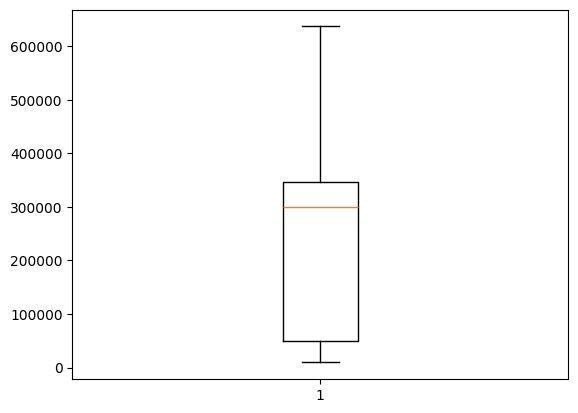

In [ ]:
plt.boxplot(df["consumption"].dropna())
plt.show()

### DA3 – q15

In [ ]:
q1 = df["consumption"].quantile(0.25)
q3 = df["consumption"].quantile(0.75)
iqr_val = q3 - q1
outliers = df[
    (df["consumption"] < (q1 - 1.5 * iqr_val))
    | (df["consumption"] > (q3 + 1.5 * iqr_val))
]

print("Number of outliers (1.5*IQR):", len(outliers))
display(outliers.head())

Number of outliers (1.5*IQR): 0


,rownames,state,statecode,year,consumption,price,eprice,oil_price,lprice,heating,income,income_per_consumption


### DA3 – q16

In [ ]:
df_no_extreme = df[
    (df["consumption"] >= (q1 - 3.0 * iqr_val))
    & (df["consumption"] <= (q3 + 3.0 * iqr_val))
]

print("Rows after removing extreme outliers (3*IQR):", len(df_no_extreme))

Rows after removing extreme outliers (3*IQR): 138


### DA3 – q17

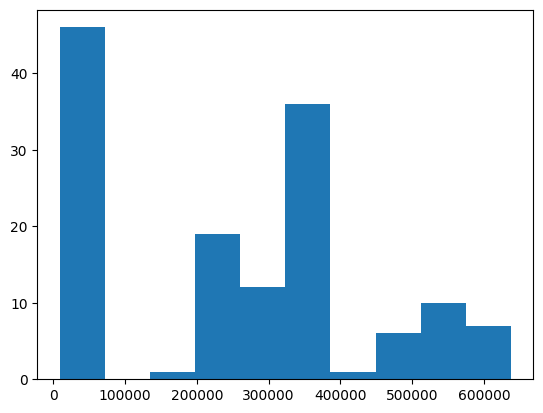

In [ ]:
plt.hist(df["consumption"].dropna())
plt.show()

### DA3 – q18

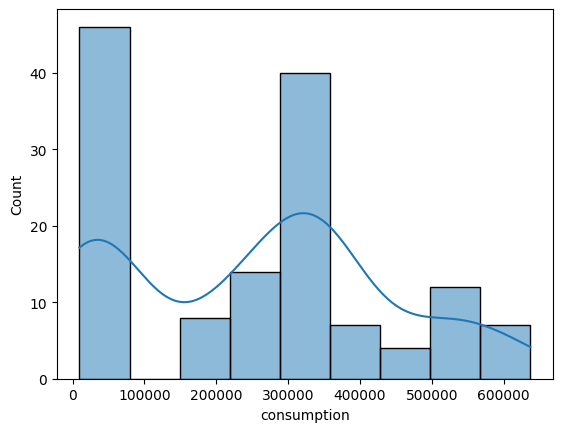

In [ ]:
sns.histplot(df["consumption"].dropna(), kde=True)
plt.show()

### DA3 – q19

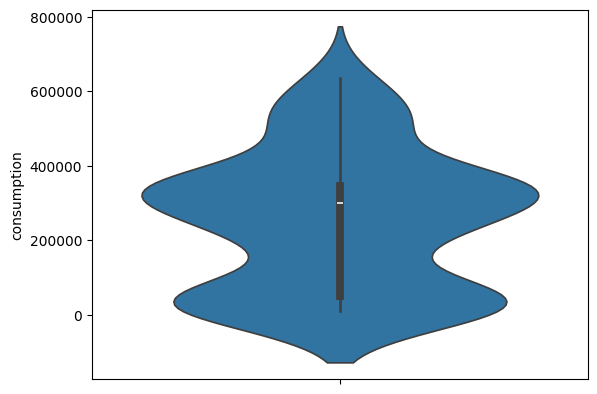

In [ ]:
sns.violinplot(y=df["consumption"])
plt.show()

### DA3 – q20

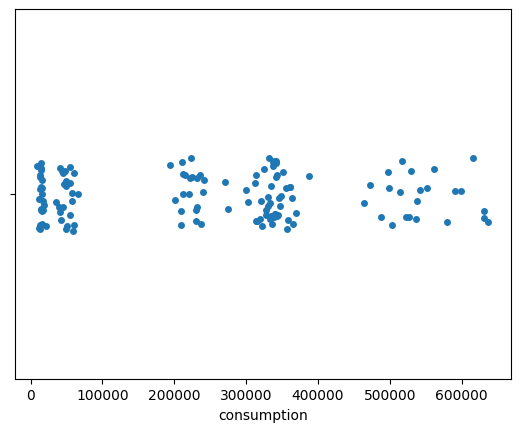

In [ ]:
sns.stripplot(x=df["consumption"])
plt.show()

### DA3 – q21

In [ ]:
freq_table = df["state"].value_counts()

display(freq_table)

,count
state,
CA,23
FL,23
MI,23
NY,23
TX,23
UT,23


### DA3 – q22

In [ ]:
prop_table = df["state"].value_counts(normalize=True)
pct_table = prop_table * 100

display(pd.DataFrame({"proportion": prop_table, "percentage": pct_table}))

,proportion,percentage
state,,
CA,0.166667,16.666667
FL,0.166667,16.666667
MI,0.166667,16.666667
NY,0.166667,16.666667
TX,0.166667,16.666667
UT,0.166667,16.666667


### DA3 – q23

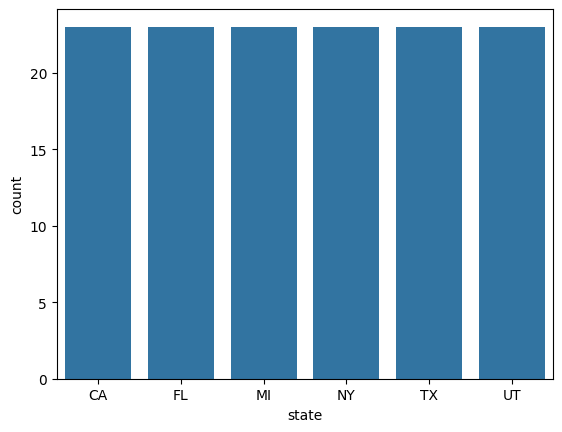

In [ ]:
sns.countplot(x="state", data=df)
plt.show()

### DA3 – q24

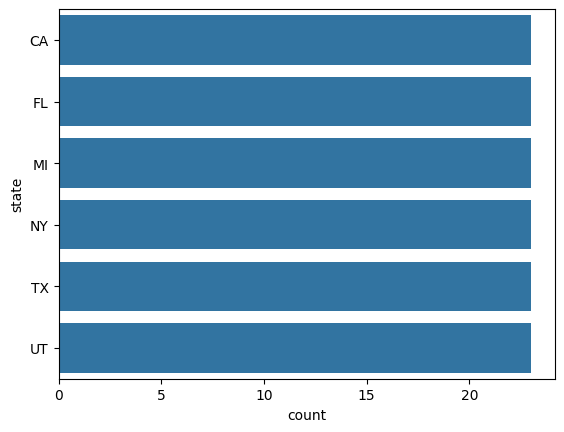

In [ ]:
sns.countplot(y="state", data=df)
plt.show()

### DA3 – q25

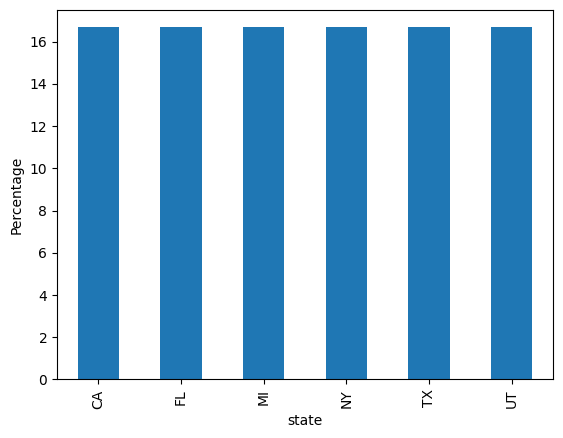

In [ ]:
pct_table.plot(kind="bar")
plt.ylabel("Percentage")
plt.show()

### DA3 – q26

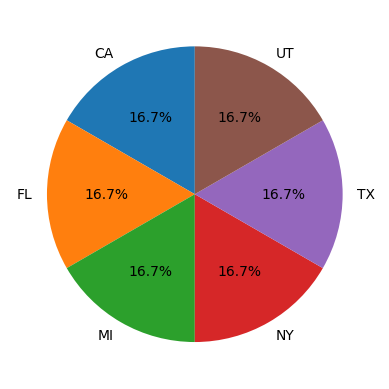

In [ ]:
df["state"].value_counts().plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.ylabel("")
plt.show()

### DA3 – q27

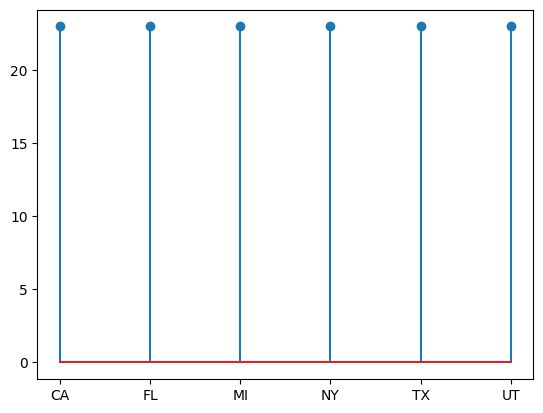

In [ ]:
counts = df["state"].value_counts()
plt.stem(counts.index, counts.values)
plt.show()

### DA3 – q28

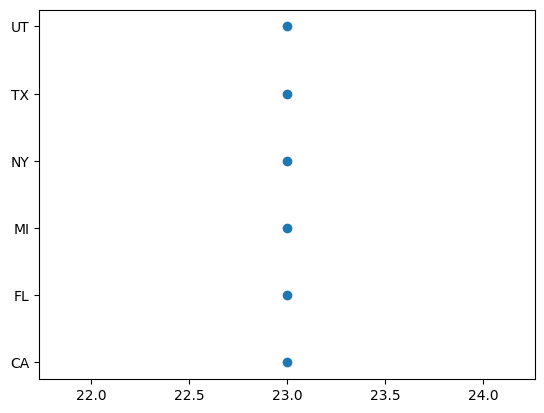

In [ ]:
plt.plot(counts.values, counts.index, "o")
plt.show()

### DA3 – q29

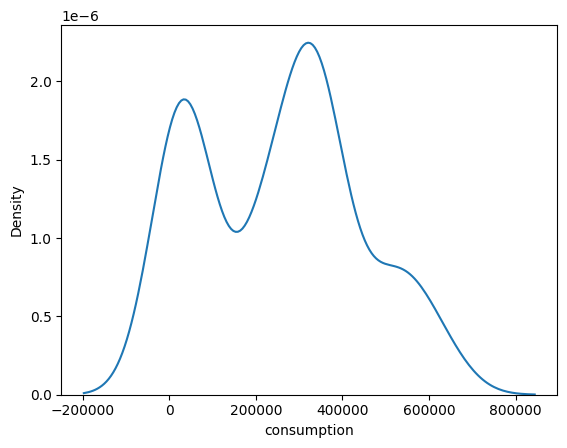

In [ ]:
sns.kdeplot(df["consumption"].dropna())
plt.show()

### DA3 – q30

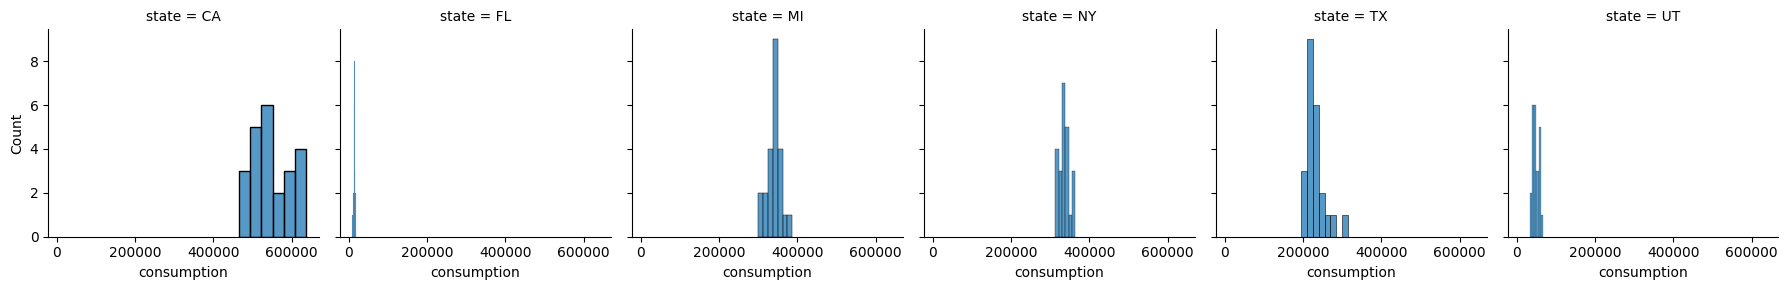

In [ ]:
g = sns.FacetGrid(df, col="state")
g.map(sns.histplot, "consumption")
plt.show()

## DA4 – Bivariate Analysis

### DA4 – q2

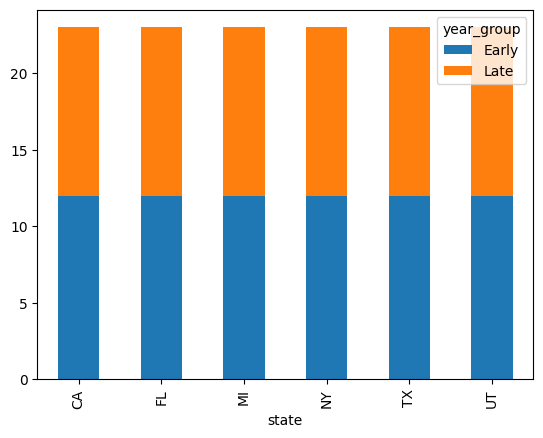

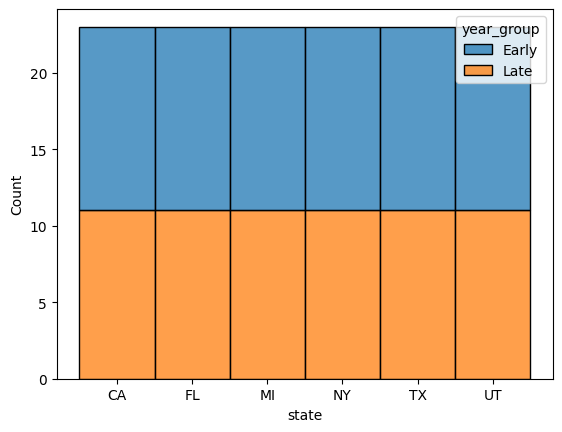

In [ ]:
df["year_group"] = pd.qcut(df["year"], q=2, labels=["Early", "Late"])
ct = pd.crosstab(df["state"], df["year_group"])
ct.plot(kind="bar", stacked=True)
plt.show()

sns.histplot(data=df, x="state", hue="year_group", multiple="stack")
plt.show()

### DA4 – q3

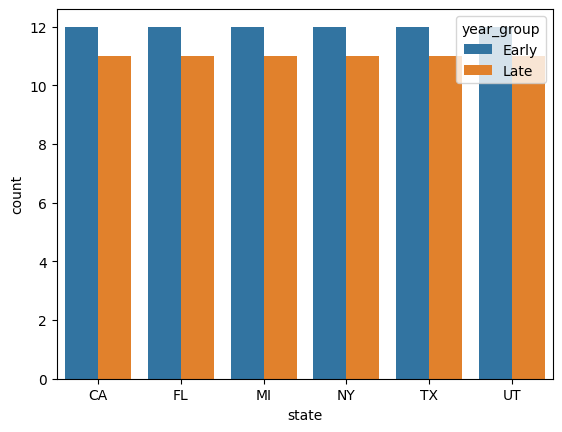

In [ ]:
sns.countplot(data=df, x="state", hue="year_group")
plt.show()

### DA4 – q4

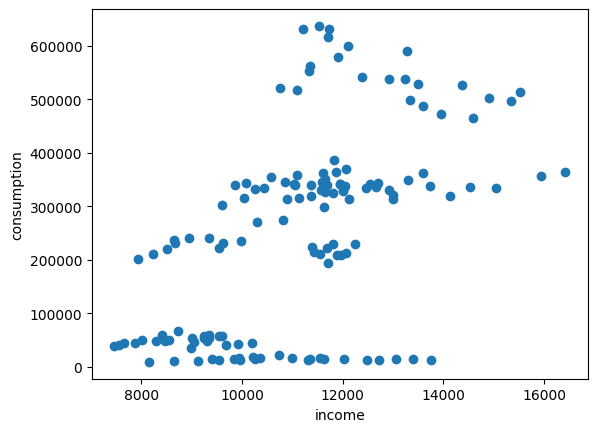

In [ ]:
plt.scatter(df["income"], df["consumption"])
plt.xlabel("income")
plt.ylabel("consumption")
plt.show()

### DA4 – q5

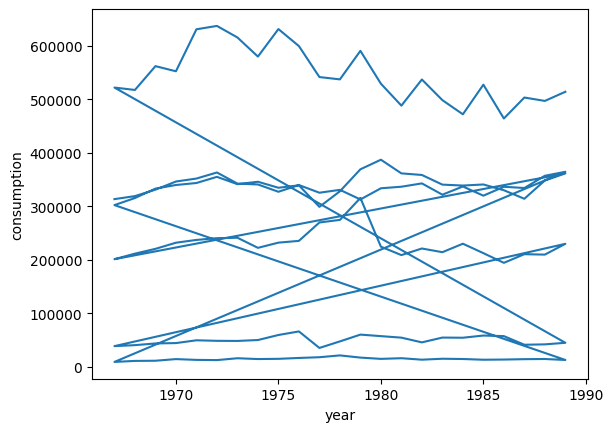

In [ ]:
plt.plot(df["year"], df["consumption"])
plt.xlabel("year")
plt.ylabel("consumption")
plt.show()

### DA4 – q6

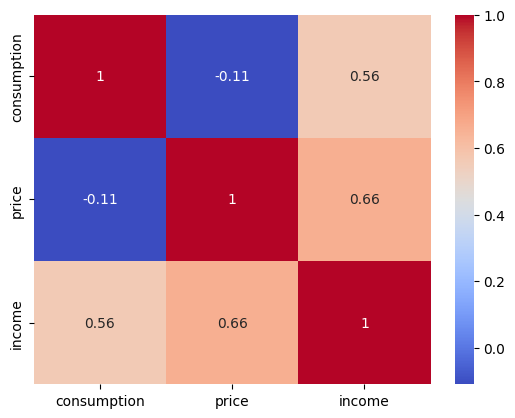

In [ ]:
sns.heatmap(
    df[["consumption", "price", "income"]].corr(), annot=True, cmap="coolwarm"
)
plt.show()

### DA4 – q7

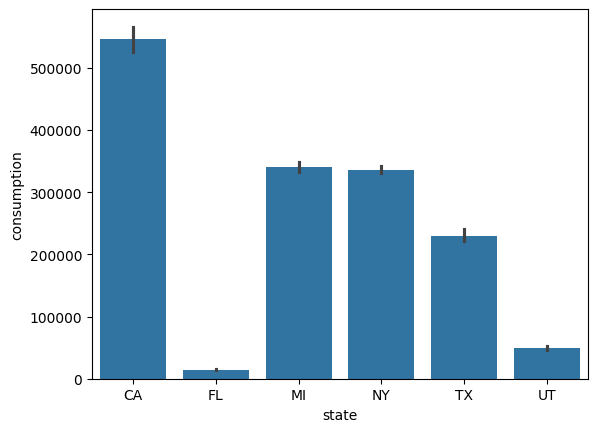

In [ ]:
sns.barplot(data=df, x="state", y="consumption")
plt.show()

### DA4 – q8

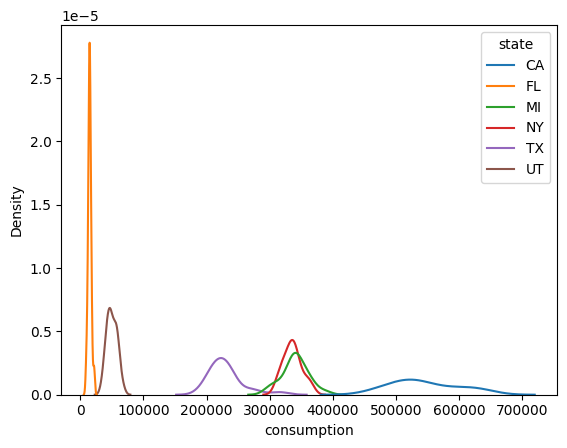

In [ ]:
sns.kdeplot(data=df, x="consumption", hue="state")
plt.show()

### DA4 – q9

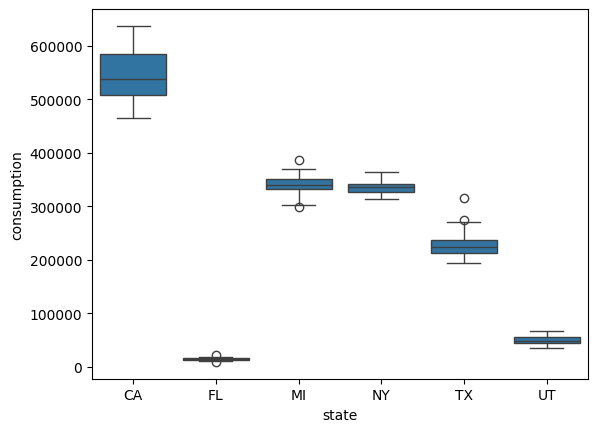

In [ ]:
sns.boxplot(data=df, x="state", y="consumption")
plt.show()

### DA4 – q10

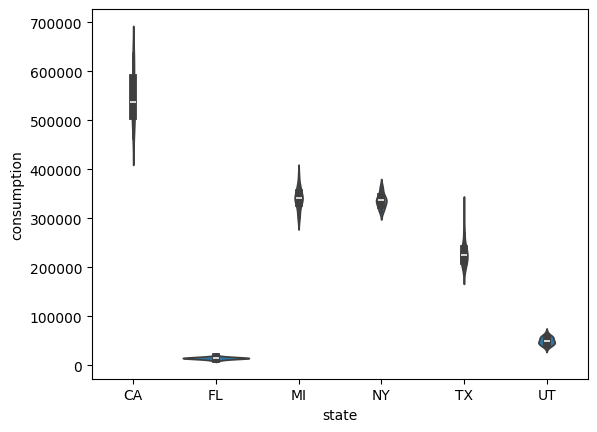

In [ ]:
sns.violinplot(data=df, x="state", y="consumption")
plt.show()

### DA4 – q11

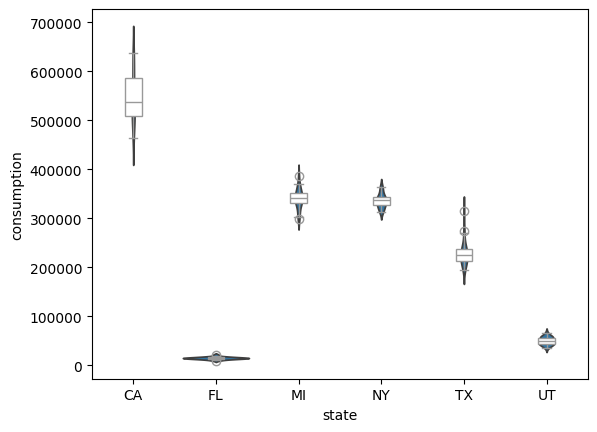

In [ ]:
sns.violinplot(data=df, x="state", y="consumption", inner=None)
sns.boxplot(data=df, x="state", y="consumption", width=0.2, color="white")
plt.show()

### DA4 – q12

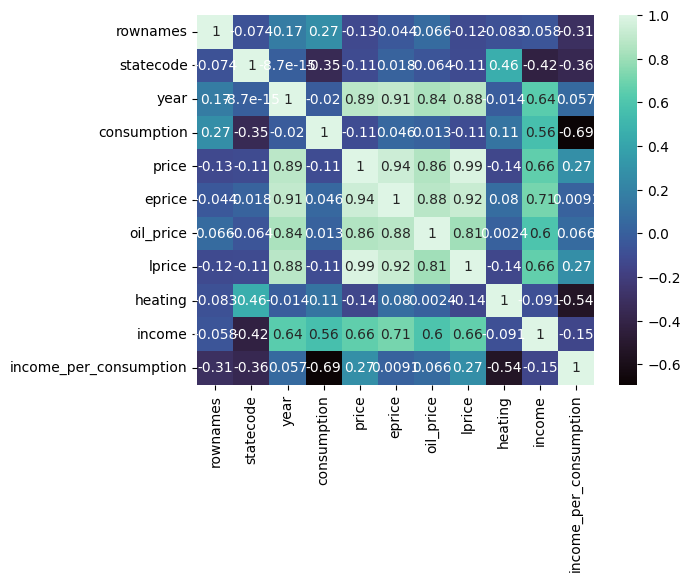

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="mako")
plt.show()

### DA4 – q13

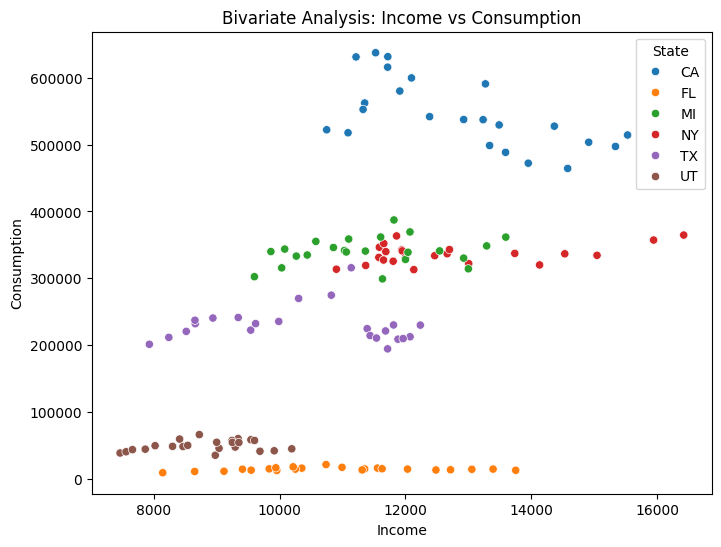

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="income", y="consumption", hue="state")
plt.title("Bivariate Analysis: Income vs Consumption")
plt.xlabel("Income")
plt.ylabel("Consumption")
plt.legend(title="State")
plt.show()

## DA5 – Multivariate Visualisation

### DA5 – q1

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print(num_cols)

['rownames', 'statecode', 'year', 'consumption', 'price', 'eprice', 'oil_price', 'lprice', 'heating', 'income', 'income_per_consumption']


### DA5 – q2

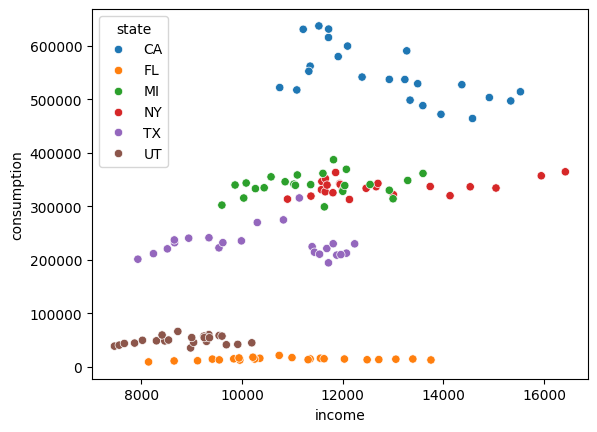

In [ ]:
sns.scatterplot(data=df, x="income", y="consumption", hue="state")
plt.show()

### DA5 – q3

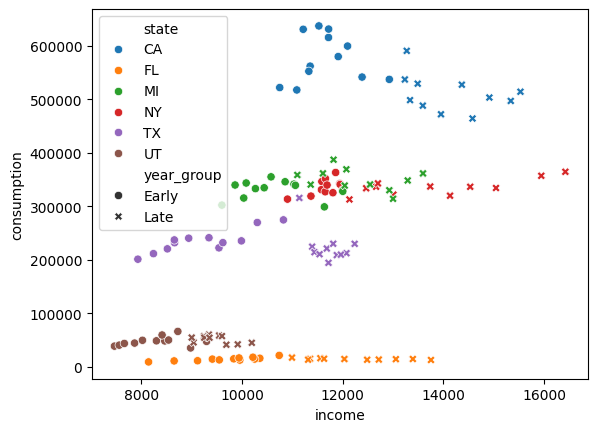

In [ ]:
sns.scatterplot(
    data=df, x="income", y="consumption", hue="state", style="year_group"
)
plt.show()

### DA5 – q4

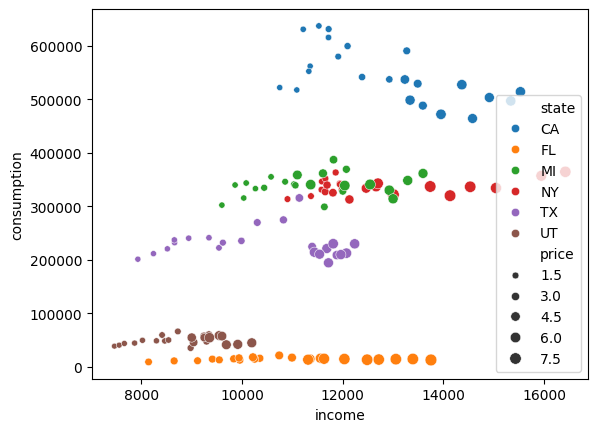

In [ ]:
sns.scatterplot(
    data=df, x="income", y="consumption", hue="state", size="price"
)
plt.show()

### DA5 – q5

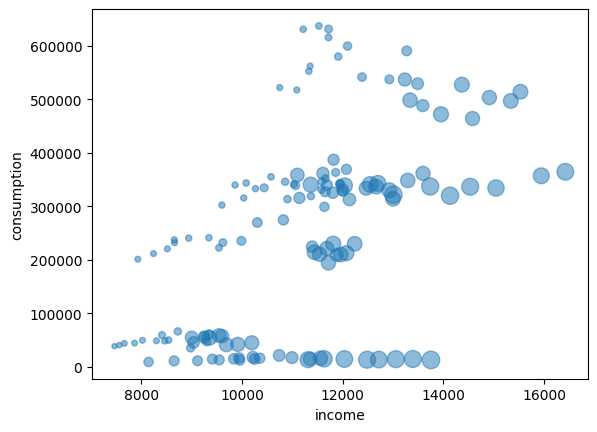

In [ ]:
plt.scatter(df["income"], df["consumption"], s=df["price"] * 20, alpha=0.5)
plt.xlabel("income")
plt.ylabel("consumption")
plt.show()

### DA5 – q6

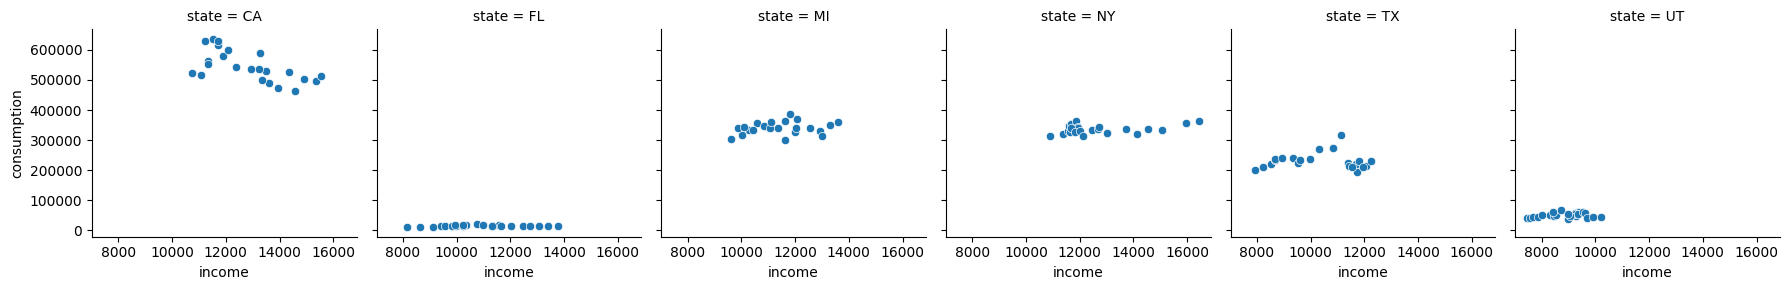

In [ ]:
g1 = sns.FacetGrid(df, col="state")
g1.map(sns.scatterplot, "income", "consumption")
plt.show()

### DA5 – q7

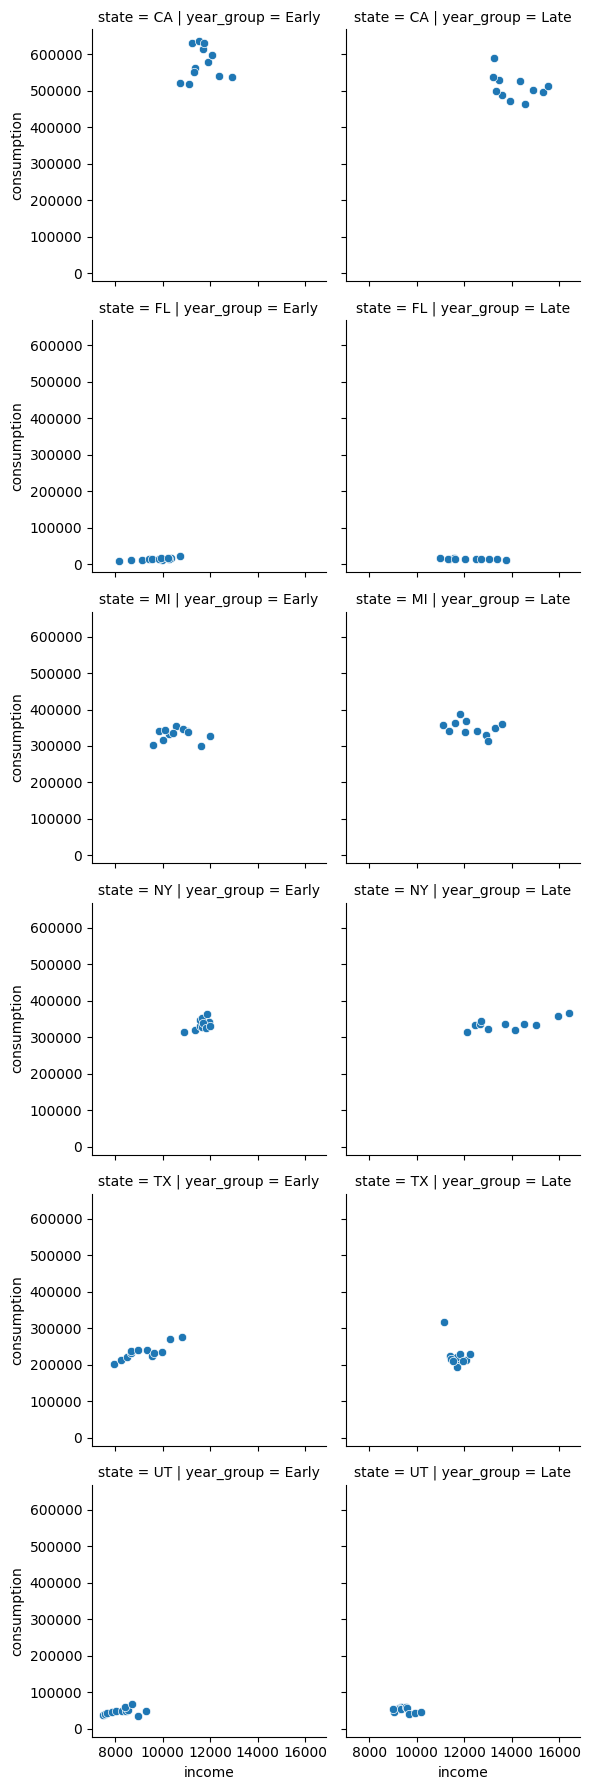

In [ ]:
g2 = sns.FacetGrid(df, row="state", col="year_group")
g2.map(sns.scatterplot, "income", "consumption")
plt.show()

### DA5 – q8

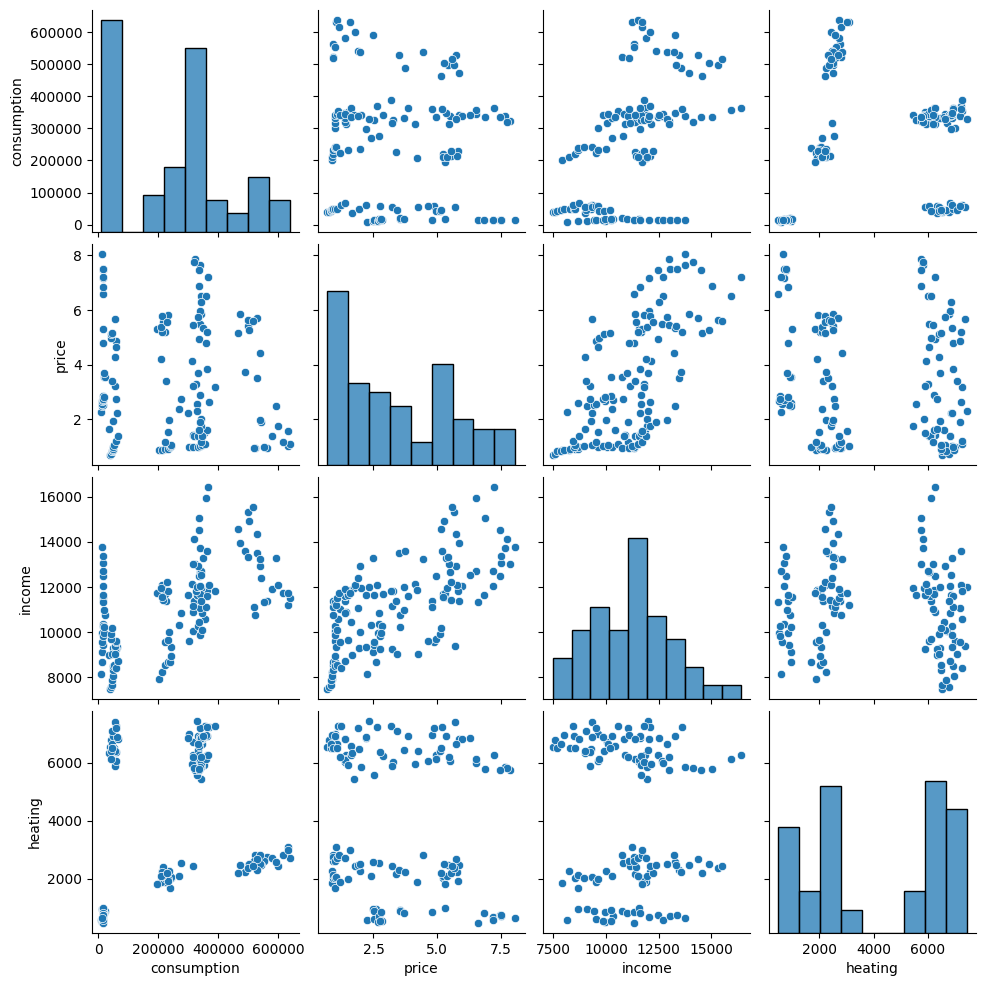

In [ ]:
sns.pairplot(df[["consumption", "price", "income", "heating"]])
plt.show()

### DA5 – q9

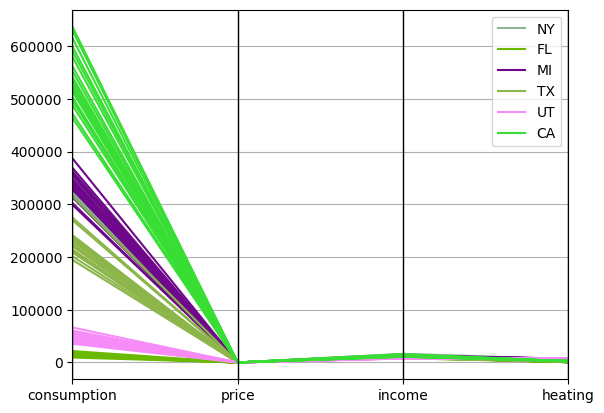

In [ ]:
df_pc = df[["consumption", "price", "income", "heating"]].copy()
df_pc["Group"] = df["state"]
parallel_coordinates(df_pc, "Group")
plt.show()

## DA6 – Time Series (AirPassengers)

### DA6 – q1

In [ ]:
air = sm.datasets.get_rdataset("AirPassengers").data

### DA6 – q2

In [ ]:
print(air.head(5))
print(air.tail(5))

          time  value
0  1949.000000    112
1  1949.083333    118
2  1949.166667    132
3  1949.250000    129
4  1949.333333    121
            time  value
139  1960.583333    606
140  1960.666667    508
141  1960.750000    461
142  1960.833333    390
143  1960.916667    432


### DA6 – q3

In [ ]:
start_time = air["time"].min()
end_time = air["time"].max()

print("Start:", start_time, "| End:", end_time)

Start: 1949.0 | End: 1960.91666666667


### DA6 – q4

In [ ]:
ts_freq = len(air)
ts_class = type(air["value"])

print("Number of observations:", ts_freq)
print("Type of series:", ts_class)

Number of observations: 144
Type of series: <class 'pandas.core.series.Series'>


### DA6 – q5

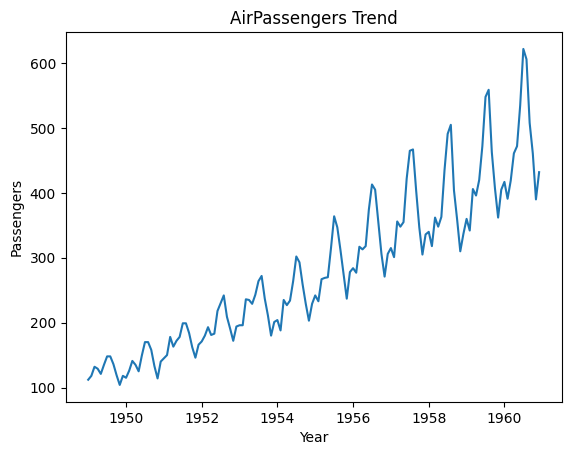

In [ ]:
plt.plot(air["time"], air["value"])
plt.title("AirPassengers Trend")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()

### DA6 – q6

In [ ]:
decomp = seasonal_decompose(air["value"], model="multiplicative", period=12)

display(pd.DataFrame({"trend": decomp.trend, "seasonal": decomp.seasonal, "resid": decomp.resid}).head(15))

,trend,seasonal,resid
0,NaN,0.910230,NaN
1,NaN,0.883625,NaN
2,NaN,1.007366,NaN
3,NaN,0.975906,NaN
4,NaN,0.981378,NaN
5,NaN,1.112776,NaN
6,126.791667,1.226556,0.951664
7,127.250000,1.219911,0.953401
8,127.958333,1.060492,1.002220
9,128.583333,0.921757,1.004028


### DA6 – q7

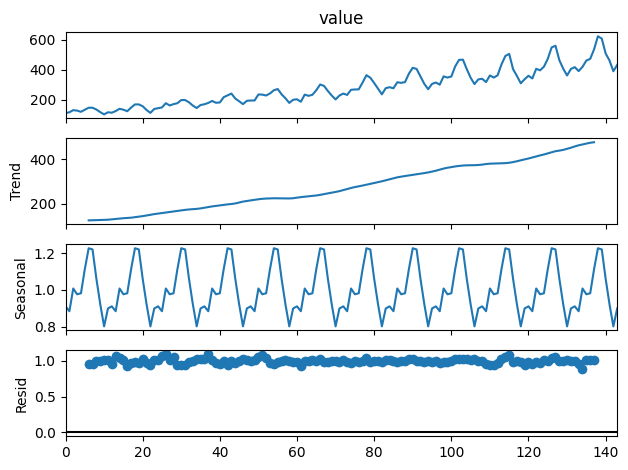

In [ ]:
decomp.plot()
plt.show()

### DA6 – q8

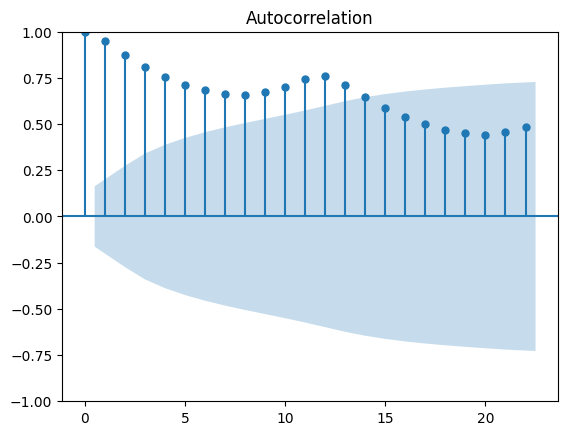

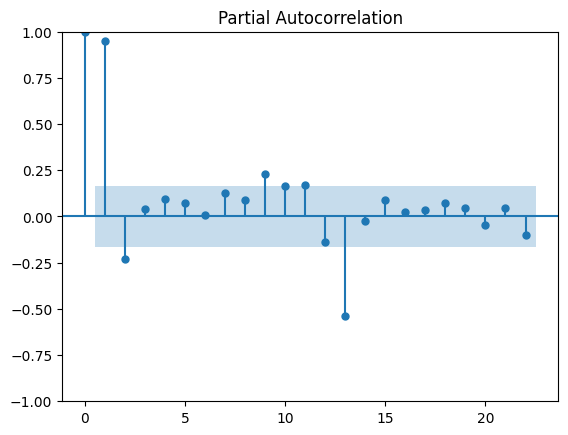

In [ ]:
plot_acf(air["value"])
plt.show()
plot_pacf(air["value"])
plt.show()

### DA6 – q9

In [ ]:
model = ARIMA(air["value"], order=(1, 1, 1))
fitted_model = model.fit()

print(fitted_model.params)

ar.L1      -0.474196
ma.L1       0.863496
sigma2    961.926976
dtype: float64


### DA6 – q10

In [ ]:
print(fitted_model.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Mon, 19 Oct 2026   AIC                           1394.683
Time:                        05:59:31   BIC                           1403.571
Sample:                             0   HQIC                          1398.294
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710       1.017
sigma2       961.9270    107.433      8.954      0.0

### DA6 – q11

In [ ]:
forecast_values = fitted_model.forecast(steps=12)

display(forecast_values)

,predicted_mean
144,475.735059
145,454.996073
146,464.830415
147,460.167010
148,462.378378
149,461.329756
150,461.827008
151,461.591213
152,461.703026
153,461.650005


### DA6 – q12

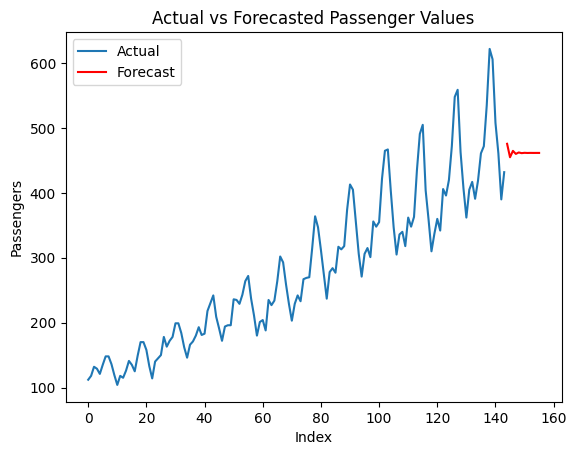

In [ ]:
plt.plot(air["value"], label="Actual")
plt.plot(
    range(len(air), len(air) + 12),
    forecast_values,
    label="Forecast",
    color="red",
)
plt.xlabel("Index")
plt.ylabel("Passengers")
plt.title("Actual vs Forecasted Passenger Values")
plt.legend()
plt.show()

## DA7 – Summary Statistics & Correlation

### DA7 – q2

In [ ]:
num_series = df["consumption"].dropna()
summary_metrics = {
    "Mean": num_series.mean(),
    "Median": num_series.median(),
    "Minimum": num_series.min(),
    "Maximum": num_series.max(),
    "Range": num_series.max() - num_series.min(),
    "Variance": num_series.var(),
    "Standard Deviation": num_series.std(),
    "IQR": num_series.quantile(0.75) - num_series.quantile(0.25),
    "Skewness": skew(num_series),
    "Kurtosis": kurtosis(num_series),
}

display(pd.Series(summary_metrics, name="consumption"))

,consumption
Mean,2.529015e+05
Median,3.008355e+05
Minimum,9.430000e+03
Maximum,6.372890e+05
Range,6.278590e+05
Variance,3.403218e+10
Standard Deviation,1.844781e+05
IQR,2.973252e+05
Skewness,1.848586e-01
Kurtosis,-9.828841e-01


### DA7 – q3

In [ ]:
summary_df = pd.DataFrame([summary_metrics])
print(summary_df)

            Mean    Median  Minimum  Maximum   Range      Variance  \
0  252901.478261  300835.5     9430   637289  627859  3.403218e+10   

   Standard Deviation        IQR  Skewness  Kurtosis  
0       184478.131559  297325.25  0.184859 -0.982884  


### DA7 – q5

In [ ]:
binned_num = pd.cut(df["consumption"], bins=5)
freq_binned = binned_num.value_counts()

display(freq_binned.sort_index())

,count
consumption,
"(8802.141, 135001.8]",46
"(135001.8, 260573.6]",20
"(260573.6, 386145.4]",48
"(386145.4, 511717.2]",7
"(511717.2, 637289.0]",17


### DA7 – q6

In [ ]:
contingency_tab = pd.crosstab(df["state"], df["year_group"])
row_pct = pd.crosstab(df["state"], df["year_group"], normalize="index")
col_pct = pd.crosstab(df["state"], df["year_group"], normalize="columns")

print("Contingency table"); display(contingency_tab)
print("Row percentages"); display(row_pct)
print("Column percentages"); display(col_pct)

Contingency table


year_group,Early,Late
state,,
CA,12,11
FL,12,11
MI,12,11
NY,12,11
TX,12,11
UT,12,11


Row percentages


year_group,Early,Late
state,,
CA,0.521739,0.478261
FL,0.521739,0.478261
MI,0.521739,0.478261
NY,0.521739,0.478261
TX,0.521739,0.478261
UT,0.521739,0.478261


Column percentages


year_group,Early,Late
state,,
CA,0.166667,0.166667
FL,0.166667,0.166667
MI,0.166667,0.166667
NY,0.166667,0.166667
TX,0.166667,0.166667
UT,0.166667,0.166667


### DA7 – q8

In [ ]:
grouped_stats = df.groupby("state")["consumption"].agg(
    ["mean", "median", "std"]
)

display(grouped_stats)

/tmp/ipykernel_2220/358352598.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_stats = df.groupby("state")["consumption"].agg(


,mean,median,std
state,,,
CA,545725.000000,537194.0,51834.867253
FL,14736.869565,14793.0,2514.031791
MI,340548.695652,340732.0,20647.313729
NY,336216.782609,336712.0,14345.050743
TX,230214.521739,224800.0,26730.126385
UT,49967.000000,48855.0,7968.202489


### DA7 – q10

Pearson: 0.5585589512330981 | Spearman: 0.5309608232170213


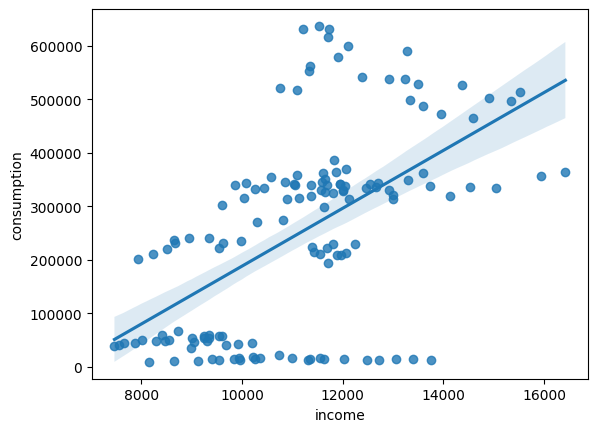

In [ ]:
valid_data = df[["consumption", "income"]].dropna()
p_corr, _ = pearsonr(valid_data["consumption"], valid_data["income"])
s_corr, _ = spearmanr(valid_data["consumption"], valid_data["income"])
print("Pearson:", p_corr, "| Spearman:", s_corr)
sns.regplot(data=valid_data, x="income", y="consumption")
plt.show()

### DA7 – q11

/tmp/ipykernel_2220/2303326161.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cat_combo_stats = df.groupby(["state", "year_group"])["consumption"].agg(


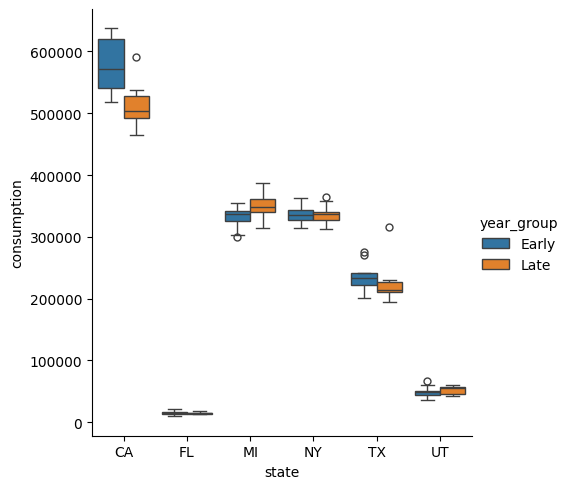

mean           std
state year_group                             
CA    Early       577384.416667  44409.866830
      Late        511187.454545  35024.406814
FL    Early        14678.333333   3328.115228
      Late         14800.727273   1308.510381
MI    Early       331663.916667  17391.599375
      Late        350241.181818  20176.844787
NY    Early       336153.166667  14185.892646
      Late        336286.181818  15209.976935
TX    Early       235082.250000  21173.260826
      Late        224904.272727  31926.622430
UT    Early        47957.583333   8548.635356
      Late         52159.090909   7011.759672

In [ ]:
cat_combo_stats = df.groupby(["state", "year_group"])["consumption"].agg(
    ["mean", "std"]
)
sns.catplot(
    data=df, x="state", y="consumption", hue="year_group", kind="box"
)
plt.show()

display(cat_combo_stats)

### DA7 – q12

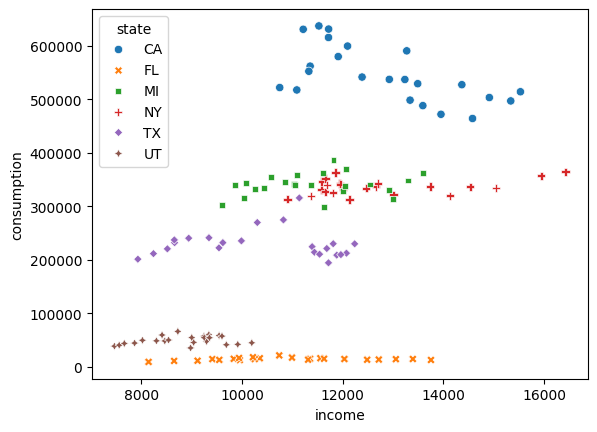

/tmp/ipykernel_2220/1625179555.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  corr_per_cat = df.groupby("state")[["income", "consumption"]].corr()


income  consumption
state                                   
CA    income       1.000000    -0.631795
      consumption -0.631795     1.000000
FL    income       1.000000     0.216015
      consumption  0.216015     1.000000
MI    income       1.000000     0.233739
      consumption  0.233739     1.000000
NY    income       1.000000     0.388648
      consumption  0.388648     1.000000
TX    income       1.000000    -0.033136
      consumption -0.033136     1.000000
UT    income       1.000000     0.250805
      consumption  0.250805     1.000000

In [ ]:
sns.scatterplot(
    data=df, x="income", y="consumption", hue="state", style="state"
)
plt.show()
corr_per_cat = df.groupby("state")[["income", "consumption"]].corr()

display(corr_per_cat)

### DA7 – q13

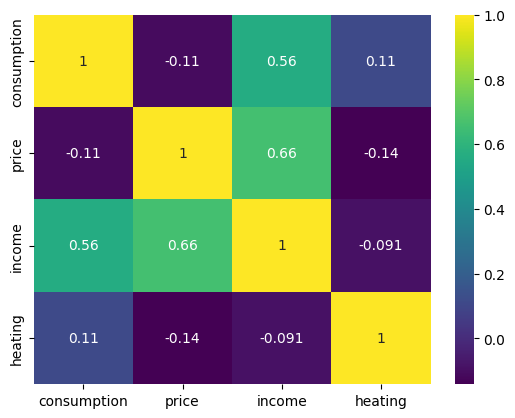

In [ ]:
full_corr_matrix = df[["consumption", "price", "income", "heating"]].corr()
sns.heatmap(full_corr_matrix, annot=True, cmap="viridis")
plt.show()

### DA7 – q14

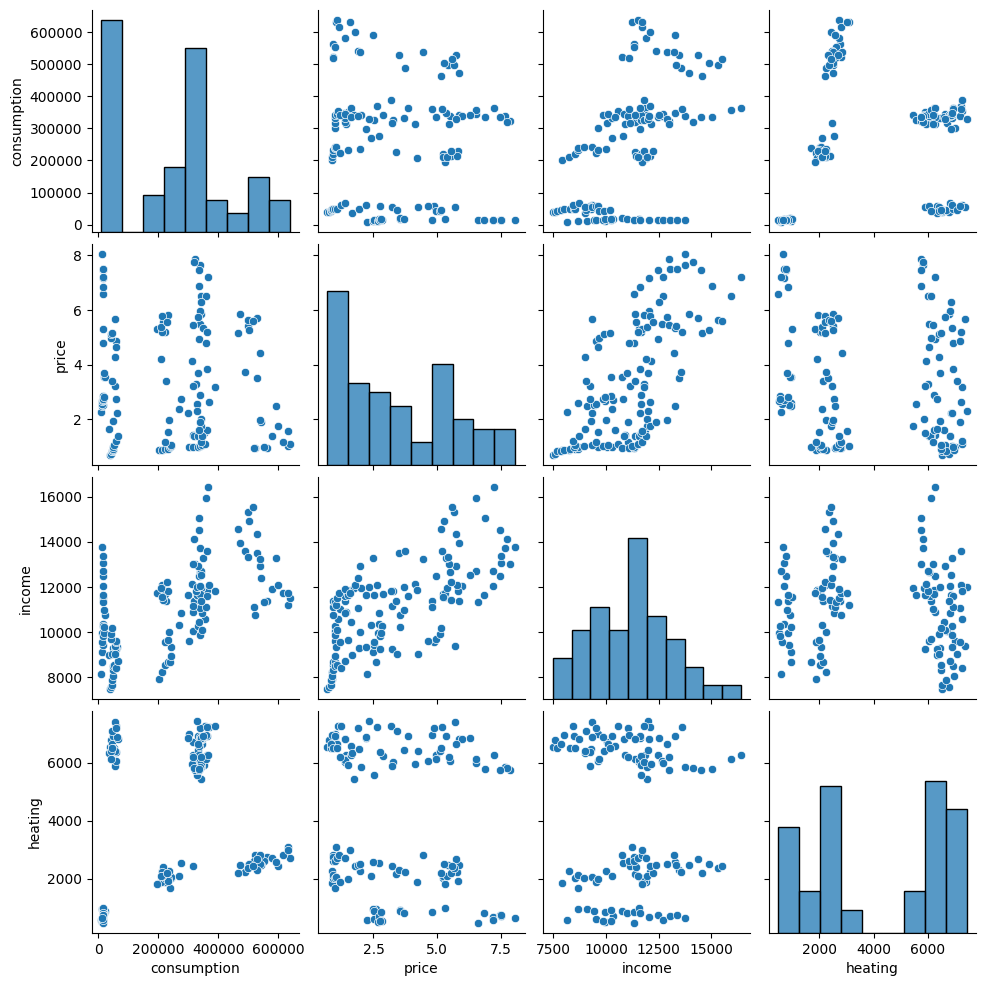

In [ ]:
sns.pairplot(df[["consumption", "price", "income", "heating"]])
plt.show()

## DA8 – Clustering (K-Means & Hierarchical)

### DA8 – q4

In [ ]:
dep_dist = df["state"].value_counts()

display(dep_dist)

,count
state,
CA,23
FL,23
MI,23
NY,23
TX,23
UT,23


### DA8 – q5

In [ ]:
num_data = df[
    ["consumption", "price", "eprice", "oil_price", "lprice", "heating", "income"]
].dropna()

print("Shape:", num_data.shape)

Shape: (138, 7)


### DA8 – q6

In [ ]:
scaler = StandardScaler()
num_scaled = scaler.fit_transform(num_data)

print("Scaled shape:", num_scaled.shape)
print("Mean ~0:", num_scaled.mean(axis=0).round(3))
print("Std ~1:", num_scaled.std(axis=0).round(3))

Scaled shape: (138, 7)
Mean ~0: [-0.  0. -0.  0.  0.  0.  0.]
Std ~1: [1. 1. 1. 1. 1. 1. 1.]


### DA8 – q7

In [ ]:
kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2.fit(num_scaled)

print(kmeans2)

KMeans(n_clusters=2, random_state=42)


### DA8 – q8

In [ ]:
km_labels = kmeans2.labels_

print(dict(zip(*np.unique(km_labels, return_counts=True))))

{np.int32(0): np.int64(77), np.int32(1): np.int64(61)}


### DA8 – q9

In [ ]:
km_centers = kmeans2.cluster_centers_

display(pd.DataFrame(km_centers, columns=num_data.columns))

,consumption,price,eprice,oil_price,lprice,heating,income
0,0.008637,-0.783235,-0.787125,-0.782727,-0.765100,0.006412,-0.507976
1,-0.010902,0.988674,0.993584,0.988032,0.965783,-0.008094,0.641216


### DA8 – q10

In [ ]:
wcss = []
for k in range(1, 11):
  km = KMeans(n_clusters=k, random_state=42)
  km.fit(num_scaled)
  wcss.append(km.inertia_)

print("WCSS:", [round(w, 2) for w in wcss])

WCSS: [966.0, 497.55, 419.89, 351.46, 285.18, 224.15, 204.24, 170.65, 153.9, 119.91]


### DA8 – q11

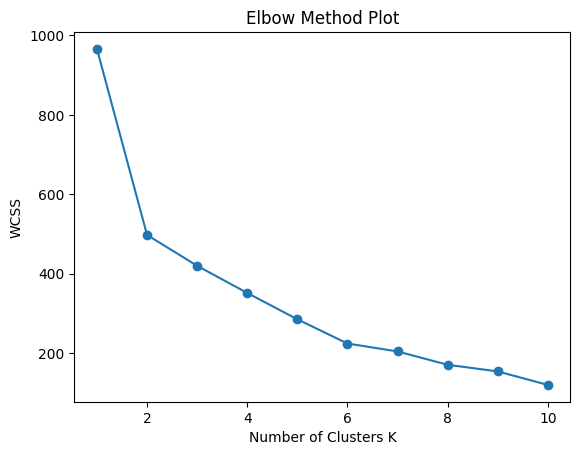

In [ ]:
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters K")
plt.ylabel("WCSS")
plt.title("Elbow Method Plot")
plt.show()

### DA8 – q12

In [ ]:
opt_k = 3
kmeans_opt = KMeans(n_clusters=opt_k, random_state=42)
opt_clusters = kmeans_opt.fit_predict(num_scaled)

print(dict(zip(*np.unique(opt_clusters, return_counts=True))))

{np.int32(0): np.int64(53), np.int32(1): np.int64(59), np.int32(2): np.int64(26)}


### DA8 – h_q6

In [ ]:
euc_dist = pdist(num_scaled, metric="euclidean")

print("Number of pairwise distances:", len(euc_dist))
print(euc_dist[:5])

Number of pairwise distances: 9453
[0.25795706 0.38775642 0.41751735 0.4839603  0.59721106]


### DA8 – h_q7

In [ ]:
ward_linkage = linkage(num_scaled, method="ward")

print(ward_linkage[:5])

[[1.17000000e+02 1.18000000e+02 8.70442996e-02 2.00000000e+00]
 [2.00000000e+00 3.00000000e+00 9.01936780e-02 2.00000000e+00]
 [7.10000000e+01 7.20000000e+01 1.08083276e-01 2.00000000e+00]
 [9.20000000e+01 9.30000000e+01 1.22286770e-01 2.00000000e+00]
 [9.40000000e+01 9.50000000e+01 1.32209975e-01 2.00000000e+00]]


### DA8 – h_q8

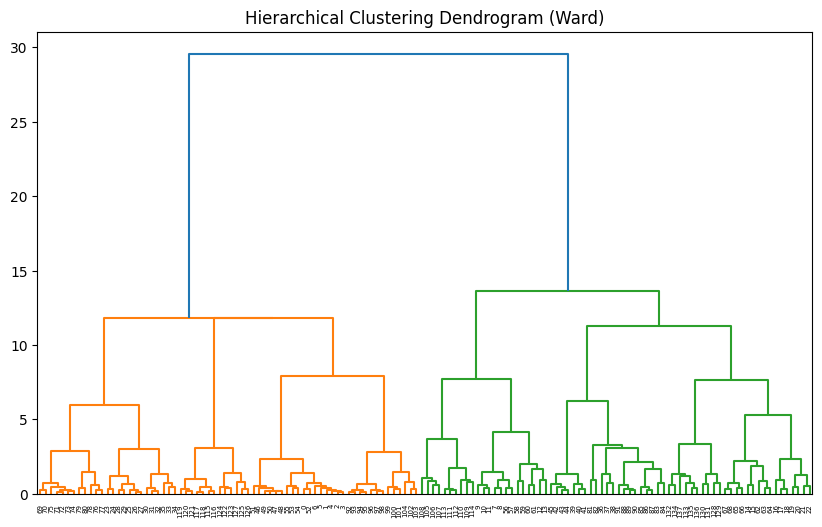

In [ ]:
plt.figure(figsize=(10, 6))
dendrogram(ward_linkage)
plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.show()

### DA8 – h_q9

In [ ]:
cluster_assignments = fcluster(ward_linkage, t=3, criterion="maxclust")

print(cluster_assignments[:30])

[1 1 1 1 1 1 1 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 1 1 1 1 1 1 1]


### DA8 – h_q10

In [ ]:
samples_per_cluster = pd.Series(cluster_assignments).value_counts()

display(samples_per_cluster)

,count
1,68
3,47
2,23


## DA9 – Principal Component Analysis

### DA9 – q2

In [ ]:
n_rows, n_cols = df.shape

print(f"Rows: {n_rows}, Columns: {n_cols}")

Rows: 138, Columns: 13


### DA9 – q3

In [ ]:
numeric_df = df[
    ["consumption", "price", "eprice", "oil_price", "lprice", "heating", "income"]
].dropna()
data_scaled = StandardScaler().fit_transform(numeric_df)

print("Scaled data shape:", data_scaled.shape)

Scaled data shape: (138, 7)


### DA9 – q4

In [ ]:
pca = PCA()
pca.fit(data_scaled)
explained_variance_ratio = pca.explained_variance_ratio_

display(pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(explained_variance_ratio))], "Explained variance ratio": explained_variance_ratio, "Cumulative": np.cumsum(explained_variance_ratio)}))

,PC,Explained variance ratio,Cumulative
0,PC1,0.605856,0.605856
1,PC2,0.197086,0.802942
2,PC3,0.145302,0.948244
3,PC4,0.032939,0.981184
4,PC5,0.011934,0.993117
5,PC6,0.005399,0.998516
6,PC7,0.001484,1.000000


### DA9 – q5

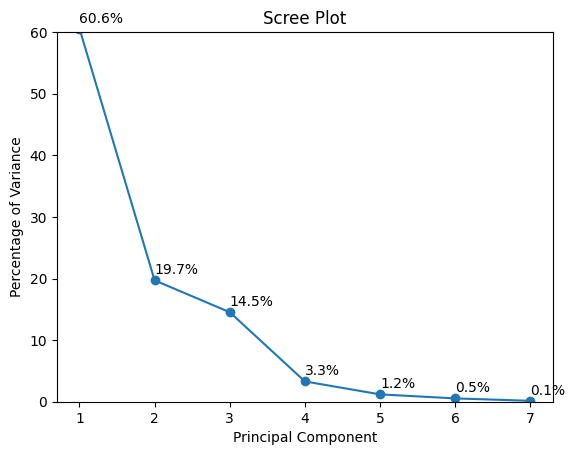

In [ ]:
var_pct = explained_variance_ratio * 100
plt.plot(range(1, len(var_pct) + 1), var_pct, marker="o")
for i, v in enumerate(var_pct):
  plt.text(i + 1, v + 1, f"{v:.1f}%")
plt.ylim(0, 60)
plt.xlabel("Principal Component")
plt.ylabel("Percentage of Variance")
plt.title("Scree Plot")
plt.show()

### DA9 – q6

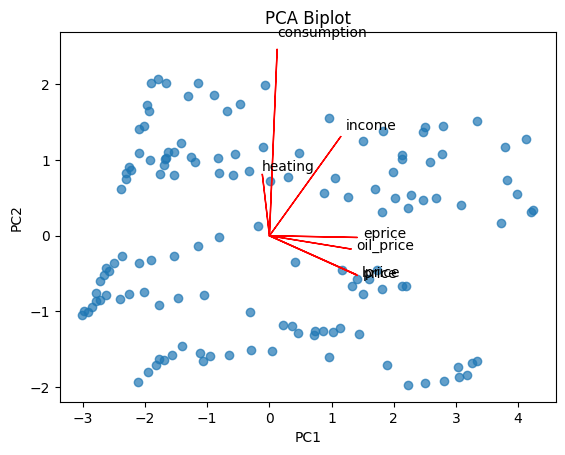

In [ ]:
pca_2d = PCA(n_components=2)
scores_2d = pca_2d.fit_transform(data_scaled)
plt.scatter(scores_2d[:, 0], scores_2d[:, 1], alpha=0.7)
loadings = pca_2d.components_.T
for i, col in enumerate(numeric_df.columns):
  plt.arrow(0, 0, loadings[i, 0] * 3, loadings[i, 1] * 3, color="r")
  plt.text(loadings[i, 0] * 3.2, loadings[i, 1] * 3.2, col)
plt.title("PCA Biplot")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### DA9 – q7

In [ ]:
pca_scores = pd.DataFrame(scores_2d, columns=["PC1", "PC2"])
print(pca_scores.head(6))

        PC1       PC2
0 -1.766604  0.811045
1 -1.691298  0.934230
2 -1.663618  1.030074
3 -1.638886  1.101689
4 -1.542248  1.110177
5 -1.419778  1.226694


### DA9 – q8

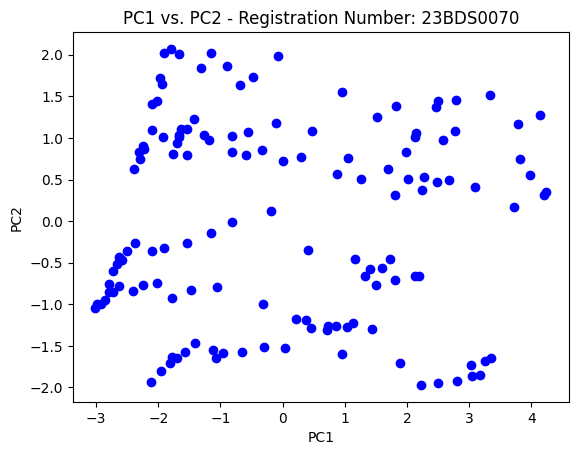

In [ ]:
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o")
plt.title("PC1 vs. PC2 - Registration Number: 23BDS0070")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [ ]:
print("""






































































































































































































































































""")